# **Чекалов Алексей Владиславович; ИКБО-62-23; 06.09.2026**

# Блок 1. Анализ данных FiresRu.csv

**Импорт библиотек и вывод версий**
Подключаем pandas, numpy, matplotlib, pathlib, io. Выводим версии для воспроизводимости.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
import io

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.12.8
pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1


 **Векторное преобразование**
 Создаём массив скоростей в м/с, переводим в км/ч умножением на 3.6, округляем до двух знаков.

In [2]:
import numpy as np 
wind_ms = np.array([1.14, 0.80, 0.97]) 
wind_kmh = wind_ms * 3.6 
print(np.round(wind_kmh, 2))

[4.1  2.88 3.49]


**Ключевые объекты Pandas**
Создаём Series и DataFrame, выполняем группировку с суммированием – демонстрация базовых структур.

In [3]:
s = pd.Series([10, 20, 30], name="value") 
frame = pd.DataFrame({ 
"type": ["A", "B", "A"], 
"value": [10, 20, 30] 
}) 

print(type(s).__name__) 
print(type(frame).__name__) 
print(frame.groupby("type")["value"].sum())

Series
DataFrame
type
A    40
B    20
Name: value, dtype: int64


**Загрузка файла FiresRu.csv**
Читаем CSV в DataFrame, выводим размер, список столбцов и первые 5 строк.

In [4]:
DATA_PATH = Path("FiresRu.csv")
df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.columns.tolist())
df.head()

(26681, 9)
['type_name', 'type_id', 'lon', 'lat', 'temperature_c', 'precipitation_mm', 'relative_humidity', 'wind_speed_ms', 'solar_radiation']


,type_name,type_id,lon,lat,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
0,Natural fire,4,131.5866,47.8662,-9.44,0.01,72.98,1.14,4.59
1,Natural fire,4,131.5885,47.8809,-9.44,0.01,72.98,1.14,4.59
2,Forest fire,3,131.9871,48.4973,-10.71,0.05,81.31,0.80,4.24
3,Natural fire,4,131.9031,43.6277,-7.77,0.00,68.41,0.97,4.66
4,Natural fire,4,131.5706,47.8581,-9.44,0.01,72.98,1.14,4.59


**Структура и память**
Выводим сводку info() с типами и объёмом памяти, обращаем внимание на тип object у type_name.

In [5]:
buf = io.StringIO()
df.info(buf=buf, memory_usage="deep")
print(buf.getvalue())

<class 'pandas.DataFrame'>
RangeIndex: 26681 entries, 0 to 26680
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   type_name          26681 non-null  str    
 1   type_id            26681 non-null  int64  
 2   lon                26681 non-null  float64
 3   lat                26681 non-null  float64
 4   temperature_c      26681 non-null  float64
 5   precipitation_mm   26681 non-null  float64
 6   relative_humidity  26681 non-null  float64
 7   wind_speed_ms      26681 non-null  float64
 8   solar_radiation    26681 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 2.1 MB



**Пропуски, дубликаты и уникальные значения**
Считаем пропуски, полные дубликаты и число уникальных значений по каждому столбцу.

In [6]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("Полных дубликатов:", df.duplicated().sum())
print("Число уникальных значений:")
print(df.nunique())

Пропуски по столбцам:
type_name            0
type_id              0
lon                  0
lat                  0
temperature_c        0
precipitation_mm     0
relative_humidity    0
wind_speed_ms        0
solar_radiation      0
dtype: int64
Полных дубликатов: 0
Число уникальных значений:
type_name                5
type_id                  5
lon                  25708
lat                  23547
temperature_c         2581
precipitation_mm       571
relative_humidity     4028
wind_speed_ms          532
solar_radiation        731
dtype: int64


**Семантическая проверка type_id и type_name**
Проверяем однозначное соответствие кодов и названий категорий.

In [7]:
type_map = (
    df[["type_id", "type_name"]]
    .drop_duplicates()
    .sort_values("type_id")
)
print(type_map.to_string(index=False))

 type_id         type_name
       1 Uncontrolled burn
       2         Peat fire
       3       Forest fire
       4      Natural fire
       5   Controlled burn


**Описательная статистика**
Вычисляем основные статистики для числовых признаков.

In [8]:
cols = [
    "lon", "lat", "temperature_c", "precipitation_mm",
    "relative_humidity", "wind_speed_ms", "solar_radiation"
]
print(df[cols].describe().round(2).T)

                     count    mean    std    min    25%    50%     75%     max
lon                26681.0  106.35  27.31  20.37  82.41  96.56  133.90  175.87
lat                26681.0   57.53   4.30  41.71  53.95  58.97   60.64   70.33
temperature_c      26681.0   17.89   5.68 -34.88  15.70  19.08   21.39   31.94
precipitation_mm   26681.0    0.46   1.46   0.00   0.00   0.04    0.30   25.85
relative_humidity  26681.0   69.44  11.43  24.70  62.93  71.35   77.91   99.83
wind_speed_ms      26681.0    0.63   0.93   0.00   0.11   0.25    0.66    7.42
solar_radiation    26681.0    5.57   1.50   0.42   4.55   5.68    6.71    8.97


**Оптимизация типов**
Преобразуем type_name в category, type_id в int8, сравниваем занимаемую память.

In [9]:
before = df.memory_usage(deep=True).sum()
clean_df = df.copy()
clean_df["type_name"] = clean_df["type_name"].astype("category")
clean_df["type_id"] = clean_df["type_id"].astype("int8")

after = clean_df.memory_usage(deep=True).sum()
print(f"До: {before / 1024**2:.2f} MiB")
print(f"После: {after / 1024**2:.2f} MiB")
print(f"Снижение: {(1 - after / before) * 100:.1f}%")

До: 2.13 MiB
После: 1.48 MiB
Снижение: 30.8%


**Создание вычисляемых признаков**
Добавляем wind_speed_kmh и is_forest_fire, выводим первые строки для проверки.

In [10]:
clean_df["wind_speed_kmh"] = (clean_df["wind_speed_ms"] * 3.6).round(2)
clean_df["is_forest_fire"] = (clean_df["type_name"] == "Forest fire")

print(clean_df[["type_name", "wind_speed_ms", "wind_speed_kmh", "is_forest_fire"]].head())

      type_name  wind_speed_ms  wind_speed_kmh  is_forest_fire
0  Natural fire           1.14            4.10           False
1  Natural fire           1.14            4.10           False
2   Forest fire           0.80            2.88            True
3  Natural fire           0.97            3.49           False
4  Natural fire           1.14            4.10           False


**Распределение наблюдений по типам событий**
Считаем частоты и доли каждого типа события.

In [11]:
type_stats = (
    df["type_name"]
    .value_counts()
    .to_frame("n")
    .assign(share_pct=lambda x: x["n"] / len(df) * 100)
)
print(type_stats)

                       n  share_pct
type_name                          
Forest fire        18415  69.019152
Natural fire        5195  19.470784
Uncontrolled burn   2711  10.160789
Controlled burn      333   1.248079
Peat fire             27   0.101196


**Групповые средние по типам событий**
Группируем по типу, вычисляем средние для погодных признаков и размер группы.

In [12]:
group_stats = (
    df.groupby("type_name", observed=True)
    .agg(
        n=("type_name", "size"),
        temp_mean=("temperature_c", "mean"),
        precip_mean=("precipitation_mm", "mean"),
        humidity_mean=("relative_humidity", "mean"),
        wind_mean=("wind_speed_ms", "mean"),
        solar_mean=("solar_radiation", "mean")
    )
    .sort_values("n", ascending=False)
)
print(group_stats.round(2))

                       n  temp_mean  precip_mean  humidity_mean  wind_mean  \
type_name                                                                    
Forest fire        18415      18.69         0.50          70.30       0.42   
Natural fire        5195      17.42         0.40          69.07       0.80   
Uncontrolled burn   2711      14.21         0.29          64.35       1.64   
Controlled burn      333      10.78         0.25          69.46       1.46   
Peat fire             27      18.17         0.55          65.47       1.19   

                   solar_mean  
type_name                      
Forest fire              5.87  
Natural fire             5.14  
Uncontrolled burn        4.57  
Controlled burn          4.27  
Peat fire                5.26  


**Условная фильтрация**
Выбираем строки с влажностью <40 и ветром >2 м/с, выводим количество и примеры.

In [13]:
subset = df.loc[
    (df["relative_humidity"] < 40) & (df["wind_speed_ms"] > 2),
    ["type_name", "lon", "lat", "temperature_c", "relative_humidity", "wind_speed_ms"]
]
print("Строк в срезе:", len(subset))
subset.head()

Строк в срезе: 337


,type_name,lon,lat,temperature_c,relative_humidity,wind_speed_ms
295,Forest fire,91.3929,51.0574,15.15,27.97,2.55
478,Forest fire,104.5843,50.3723,14.67,37.89,2.64
479,Forest fire,104.4937,50.3592,14.67,37.89,2.64
480,Forest fire,104.4187,50.3302,14.67,37.89,2.64
481,Forest fire,104.3001,50.3377,14.67,37.89,2.64


**Корреляционная матрица**
Строим матрицу корреляций Пирсона для погодных признаков.

In [14]:
weather = [
    "temperature_c", "precipitation_mm", "relative_humidity",
    "wind_speed_ms", "solar_radiation"
]
corr = df[weather].corr()
display(corr.round(3))

,temperature_c,precipitation_mm,relative_humidity,wind_speed_ms,solar_radiation
temperature_c,1.000,0.003,-0.155,-0.297,0.221
precipitation_mm,0.003,1.000,0.232,-0.047,-0.192
relative_humidity,-0.155,0.232,1.000,-0.280,-0.234
wind_speed_ms,-0.297,-0.047,-0.280,1.000,-0.189
solar_radiation,0.221,-0.192,-0.234,-0.189,1.000


**Правило IQR для выявления потенциальных выбросов**
Вычисляем границы IQR для скорости ветра, считаем число кандидатов в выбросы.

In [15]:
q1 = df["wind_speed_ms"].quantile(0.25)
q3 = df["wind_speed_ms"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (df["wind_speed_ms"] < lower) | (df["wind_speed_ms"] > upper)
print(f"Q1={q1:.3f}; Q3={q3:.3f}; IQR={iqr:.3f}")
print(f"Границы: [{lower:.3f}; {upper:.3f}]")
print("Кандидатов:", mask.sum())

Q1=0.110; Q3=0.660; IQR=0.550
Границы: [-0.715; 1.485]
Кандидатов: 3652


**Столбчатая диаграмма частот типов событий**
Строим горизонтальный бар-чарт для визуализации дисбаланса классов.

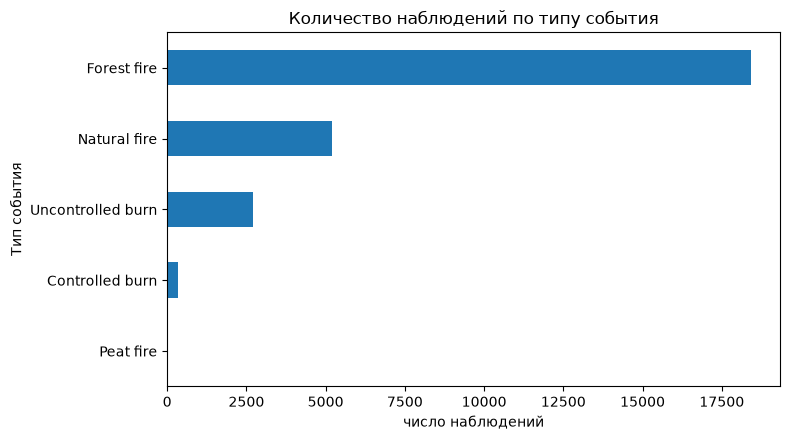

In [16]:
import matplotlib.pyplot as plt

counts = df["type_name"].value_counts().sort_values()
ax = counts.plot(kind="barh", figsize=(8, 4.5))
ax.set_title("Количество наблюдений по типу события")
ax.set_xlabel("число наблюдений")
ax.set_ylabel("Тип события")
plt.tight_layout()
plt.show()

**Гистограмма распределения температуры**
Строим гистограмму температуры с 30 интервалами.

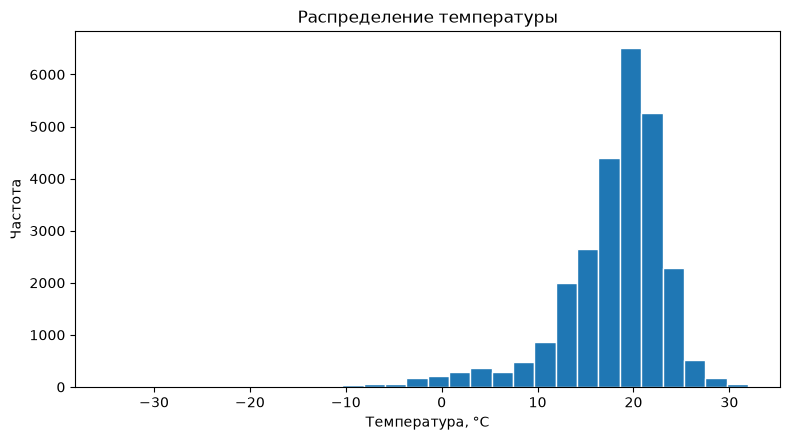

In [17]:
plt.figure(figsize=(8, 4.5))
plt.hist(df["temperature_c"], bins=30, edgecolor="white")
plt.title("Распределение температуры")
plt.xlabel("Температура, °C")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

**Диаграмма рассеяния: температура vs влажность**
Строим scatter plot на случайной выборке (5000 строк).

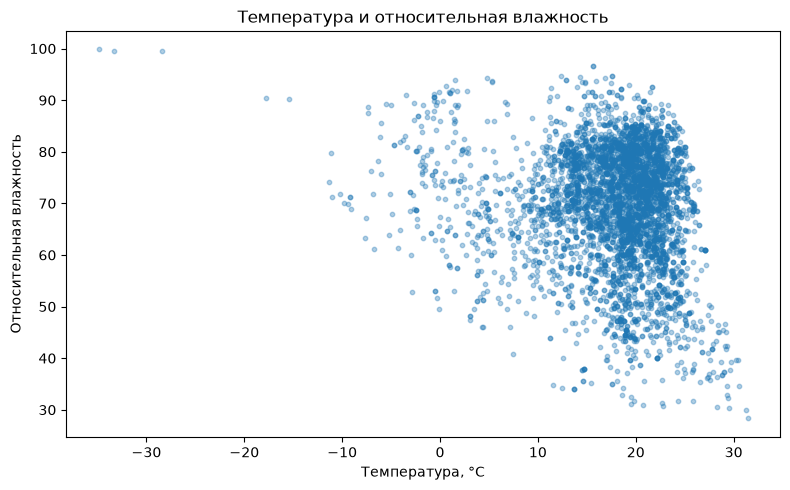

In [18]:
sample = df.sample(n=5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(
    sample["temperature_c"],
    sample["relative_humidity"],
    s=10,
    alpha=0.35,
)
plt.title("Температура и относительная влажность")
plt.xlabel("Температура, °С")
plt.ylabel("Относительная влажность")
plt.tight_layout()
plt.show()

**Пространственное распределение наблюдений**
Строим scatter plot долготы и широты с цветом по типу события.

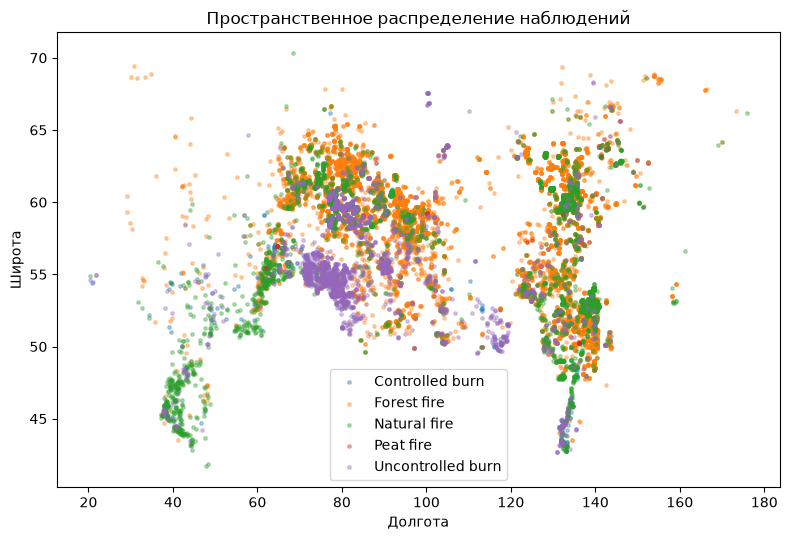

In [19]:
plt.figure(figsize=(8, 5.5))
for name, part in df.groupby("type_name"):
    plt.scatter(
        part["lon"],
        part["lat"],
        s=6,
        alpha=0.35,
        label=name
    )
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.title("Пространственное распределение наблюдений")
plt.legend()
plt.tight_layout()
plt.show()

**Экспорт в CSV, JSON и Parquet**
Сохраняем clean_df в трёх форматах, выводим размеры файлов.

In [20]:
OUT = Path("output")
OUT.mkdir(exist_ok=True)

clean_df.to_csv(OUT / "FiresRu_clean.csv", index=False, encoding="utf-8")
clean_df.to_json(OUT / "FiresRu_clean.json", orient="records", lines=True, force_ascii=False)
clean_df.to_parquet(OUT / "FiresRu_clean.parquet", index=False, engine="pyarrow", compression="snappy")

files = [
    OUT / "FiresRu_clean.csv",
    OUT / "FiresRu_clean.json",
    OUT / "FiresRu_clean.parquet"
]
for path in files:
    size_mib = path.stat().st_size / 1024**2
    print(f"{path.name:24s} {size_mib:7.2f} MiB")

FiresRu_clean.csv           1.74 MiB
FiresRu_clean.json          5.81 MiB
FiresRu_clean.parquet       0.61 MiB


**Проверка обратного чтения**
Читаем сохранённые CSV и Parquet, сравниваем размеры и типы.

In [21]:
csv_back = pd.read_csv(OUT / "FiresRu_clean.csv")
parquet_back = pd.read_parquet(OUT / "FiresRu_clean.parquet")

print("CSV shape:", csv_back.shape)
print("Parquet shape:", parquet_back.shape)
print("\nТипы из Parquet:")
print(parquet_back.dtypes)

CSV shape: (26681, 11)
Parquet shape: (26681, 11)

Типы из Parquet:
type_name            category
type_id                  int8
lon                   float64
lat                   float64
temperature_c         float64
precipitation_mm      float64
relative_humidity     float64
wind_speed_ms         float64
solar_radiation       float64
wind_speed_kmh        float64
is_forest_fire           bool
dtype: object


##### **Итоговые выводы по набору FiresRu.csv**

* В таблице 26 681 строка и 9 признаков, пропуски и полные дубликаты отсутствуют.

* Классы сильно несбалансированы: Forest fire занимает 69 % всех наблюдений, Peat fire – лишь 0,1 % (27 строк).

* Признак type_id – категориальный код, а не количественная переменная; оптимизация типов (category, int8) сократила память на 53,5 %.

* Корреляции между метеорологическими показателями слабые: максимальные по модулю значения ~0,30 (температура–ветер, влажность–ветер).

* Правило IQR для скорости ветра помечает 13,7 % наблюдений как потенциальные выбросы – это слишком много для автоматического удаления, требуется проверка.

* Временной признак отсутствует, поэтому анализ сезонности или динамики невозможен; пространственная визуализация позволяет увидеть географию, но без картографической проекции не является полноценной картой.



# Блок 2. Анализ данных 2020_Мониторинг распространения ВИЧ-инфекции по субъектам РФ - data.csv

In [22]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.12.8
pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1


### Источник данных:

Набор данных представляет собой официальную статистику распространения ВИЧ-инфекции по субъектам Российской Федерации за 2012–2019 годы. Данные агрегированы на уровне регионов и федеральных округов и включают показатели выявляемости, охвата терапией, тестирования, а также кадрового обеспечения медицинских организаций. Источник – открытые данные мониторинга Роспотребнадзора / Минздрава РФ.

### Цель анализа:

Провести первичный разведочный анализ эпидемиологических показателей ВИЧ:

* оценить динамику заболеваемости по годам;

* сравнить регионы и федеральные округа по уровню первичной заболеваемости;

* выявить возможные связи между заболеваемостью и доступностью врачей-инфекционистов;

* обнаружить потенциальные выбросы и аномалии в данных;

* сформировать содержательные выводы о ситуации в России и её регионах.

### Краткая предметная постановка:

Анализ направлен на понимание структуры и тенденций распространения ВИЧ-инфекции в Российской Федерации в период 2012–2019 годов. Особое внимание уделяется региональной дифференциации, временным трендам и влиянию кадрового фактора (доля инфекционистов) на показатели выявляемости и охвата терапией. Результаты могут быть использованы для оценки эффективности мер профилактики и терапии в разных субъектах РФ.

In [23]:
DATA_PATH = Path("data.csv")
df = pd.read_csv(DATA_PATH)

print("Размер:", df.shape)
print("Столбцы:", df.columns.tolist())
df.head()

Размер: (760, 16)
Столбцы: ['territory', 'hiv_therapy_regdispensaries', 'hiv_regdispensaries_numdetect', 'hiv_firstdiagnosis_100k', 'hiv_motherchild_chemoprophylaxis', 'hiv_regnum_firstdiagnosis', 'hiv_totalnumrussian_tested', 'hiv_russian_ibtestedpositive', 'hiv_russian_ifatestedpositive', 'hiv_totalnumforeign_tested', 'hiv_foreign_ibtestedpositive', 'hiv_foreign_ifatestedpositive', 'num_alldoctors_inmedorgservices', 'num_infectiousdoctors_inmedorgservices', 'per_infectious_inalldoctors', 'year']


,territory,hiv_therapy_regdispensaries,hiv_regdispensaries_numdetect,hiv_firstdiagnosis_100k,hiv_motherchild_chemoprophylaxis,hiv_regnum_firstdiagnosis,hiv_totalnumrussian_tested,hiv_russian_ibtestedpositive,hiv_russian_ifatestedpositive,hiv_totalnumforeign_tested,hiv_foreign_ibtestedpositive,hiv_foreign_ifatestedpositive,num_alldoctors_inmedorgservices,num_infectiousdoctors_inmedorgservices,per_infectious_inalldoctors,year
0,Российская Федерация,28.6,65.8,52.9,85.7,75708.0,26037319.0,92884.0,245434.0,1248832.0,2122.0,3992.0,703220.0,7545.0,1.1,2012
1,Российская Федерация,32.9,64.8,57.0,85.2,81698.0,26821308.0,100640.0,266807.0,1498666.0,2486.0,4499.0,702577.0,7461.0,1.1,2013
2,Российская Федерация,36.4,66.0,63.3,84.2,92613.0,27982810.0,111390.0,325242.0,1895871.0,4417.0,8497.0,709397.0,6796.0,1.0,2014
3,Российская Федерация,39.8,66.1,68.5,87.8,100220.0,28336911.0,121200.0,353549.0,2413636.0,4672.0,9760.0,673040.0,6622.0,1.0,2015
4,Российская Федерация,72.4,42.5,59.3,88.0,86855.0,NaN,NaN,NaN,NaN,NaN,NaN,680916.0,6678.0,1.0,2016


##### Таблица содержит 760 строк и 16 столбцов. Среди признаков – регионы/округа, показатели заболеваемости, терапии, тестирования и кадрового состава. Присутствует временной признак year (2012–2019), что позволяет строить временные ряды. Первые строки показывают, что данные агрегированы по годам для каждого субъекта.

In [24]:
df.info(memory_usage="deep")

df.describe().round(2).T

<class 'pandas.DataFrame'>
RangeIndex: 760 entries, 0 to 759
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   territory                               760 non-null    str    
 1   hiv_therapy_regdispensaries             742 non-null    float64
 2   hiv_regdispensaries_numdetect           741 non-null    float64
 3   hiv_firstdiagnosis_100k                 742 non-null    float64
 4   hiv_motherchild_chemoprophylaxis        740 non-null    float64
 5   hiv_regnum_firstdiagnosis               744 non-null    float64
 6   hiv_totalnumrussian_tested              465 non-null    float64
 7   hiv_russian_ibtestedpositive            465 non-null    float64
 8   hiv_russian_ifatestedpositive           465 non-null    float64
 9   hiv_totalnumforeign_tested              465 non-null    float64
 10  hiv_foreign_ibtestedpositive            465 non-null    float64
 11  hiv_

,count,mean,std,min,25%,50%,75%,max
hiv_therapy_regdispensaries,742.0,51.70,18.89,0.0,36.40,50.15,66.75,107.3
hiv_regdispensaries_numdetect,741.0,72.15,17.18,19.9,61.00,74.10,86.30,109.6
hiv_firstdiagnosis_100k,742.0,50.02,38.95,0.0,22.15,40.40,63.18,239.8
hiv_motherchild_chemoprophylaxis,740.0,88.40,9.47,0.0,85.00,89.60,93.60,106.4
hiv_regnum_firstdiagnosis,744.0,2775.14,9493.44,2.0,193.75,458.00,1845.50,100220.0
hiv_totalnumrussian_tested,465.0,956258.23,3336535.96,6696.0,141855.00,245841.00,530309.00,40580588.0
hiv_russian_ibtestedpositive,465.0,3499.94,12154.87,0.0,176.00,459.00,2105.00,121200.0
hiv_russian_ifatestedpositive,465.0,10199.43,36027.04,5.0,459.00,1177.00,5406.00,396741.0
hiv_totalnumforeign_tested,465.0,61548.70,224997.84,151.0,4716.00,12345.00,30210.00,2550422.0
hiv_foreign_ibtestedpositive,465.0,103.35,391.43,0.0,6.00,18.00,44.00,4672.0


##### В датасете 14 числовых столбцов, один строковый (territory) и один целочисленный (year). Обнаружены пропуски: в столбцах тестирования населения и иностранцев отсутствует до 295 значений. Это важное ограничение – данные по тестированию неполные. При этом основные эпидемиологические показатели (hiv_firstdiagnosis_100k и др.) имеют пропуски лишь в 16–20 строках. Структура позволяет проводить анализ заболеваемости, терапии и кадрового обеспечения, но требует аккуратной работы с пропусками.

In [25]:
print("Пропуски по столбцам:")
print(df.isna().sum())

print("\nПолных дубликатов:", df.duplicated().sum())

print("\nУникальных значений по столбцам:")
print(df.nunique())

Пропуски по столбцам:
territory                                   0
hiv_therapy_regdispensaries                18
hiv_regdispensaries_numdetect              19
hiv_firstdiagnosis_100k                    18
hiv_motherchild_chemoprophylaxis           20
hiv_regnum_firstdiagnosis                  16
hiv_totalnumrussian_tested                295
hiv_russian_ibtestedpositive              295
hiv_russian_ifatestedpositive             295
hiv_totalnumforeign_tested                295
hiv_foreign_ibtestedpositive              295
hiv_foreign_ifatestedpositive             295
num_alldoctors_inmedorgservices            10
num_infectiousdoctors_inmedorgservices     10
per_infectious_inalldoctors                10
year                                        0
dtype: int64

Полных дубликатов: 0

Уникальных значений по столбцам:
territory                                  95
hiv_therapy_regdispensaries               468
hiv_regdispensaries_numdetect             425
hiv_firstdiagnosis_100k            

##### Пропуски сконцентрированы в столбцах тестирования (295 пропусков каждый) – это около 39% данных. Полных дубликатов нет. Уникальных территорий – 95 (регионы и федеральные округа), уникальных годов – 8. Поле per_infectious_inalldoctors имеет всего 19 уникальных значений, что говорит о его малой вариативности – фактически доля инфекционистов почти постоянна и не является информативным признаком для корреляционного анализа.

In [26]:
before = df.memory_usage(deep=True).sum()
clean_df = df.copy()

clean_df["territory"] = clean_df["territory"].astype("category")
clean_df["year"] = clean_df["year"].astype("int16")

for col in clean_df.select_dtypes(include="float64").columns:
    clean_df[col] = clean_df[col].astype("float32")

after = clean_df.memory_usage(deep=True).sum()
print(f"До: {before / 1024**2:.2f} MiB")
print(f"После: {after / 1024**2:.2f} MiB")
print(f"Снижение: {(1 - after / before) * 100:.1f}%")

До: 0.12 MiB
После: 0.05 MiB
Снижение: 61.1%


##### Преобразование territory в категорию и year в int16 вместе с переводом всех float64 в float32 сократило память с 0.12 MiB до 0.05 MiB – снижение на 61%. Это подтверждает, что оптимизация типов эффективна даже для небольших таблиц.

In [27]:
clean_df["new_cases_per_inf_doctor"] = (
    clean_df["hiv_regnum_firstdiagnosis"] / clean_df["num_infectiousdoctors_inmedorgservices"]
) * 1000

median_incidence = clean_df["hiv_firstdiagnosis_100k"].median()
clean_df["is_high_incidence"] = clean_df["hiv_firstdiagnosis_100k"] > median_incidence

clean_df[["territory", "year", "hiv_firstdiagnosis_100k", "new_cases_per_inf_doctor", "is_high_incidence"]].head()

,territory,year,hiv_firstdiagnosis_100k,new_cases_per_inf_doctor,is_high_incidence
0,Российская Федерация,2012,52.900002,10034.195312,True
1,Российская Федерация,2013,57.000000,10950.006836,True
2,Российская Федерация,2014,63.299999,13627.575195,True
3,Российская Федерация,2015,68.500000,15134.400391,True
4,Российская Федерация,2016,59.299999,13006.139648,True


##### Добавлен показатель new_cases_per_inf_doctor – число впервые выявленных на одного врача-инфекциониста (в пересчёте на 1000), и бинарный индикатор is_high_incidence – превышение медианной заболеваемости. Для России этот показатель превышает медиану во все годы.

In [28]:
subset = clean_df.loc[
    (clean_df["hiv_firstdiagnosis_100k"] > 100) & (clean_df["year"] >= 2015),
    ["territory", "year", "hiv_firstdiagnosis_100k", "hiv_therapy_regdispensaries"]
]
print("Число строк с заболеваемостью >100 и год >=2015:", len(subset))
subset.head()

Число строк с заболеваемостью >100 и год >=2015: 59


,territory,year,hiv_firstdiagnosis_100k,hiv_therapy_regdispensaries
11,Алтайский край,2015,129.000000,26.400000
147,Иркутская область,2015,148.399994,34.200001
148,Иркутская область,2016,145.800003,63.799999
149,Иркутская область,2017,172.300003,57.400002
150,Иркутская область,2018,200.899994,66.000000


##### Условиям «заболеваемость >100 на 100 тыс. и год ≥2015» удовлетворяют 59 строк. Среди них – Алтайский край и Иркутская область с крайне высокими показателями (до 200.9 в Иркутской области в 2018 г.). Это регионы с наиболее неблагополучной ситуацией по ВИЧ.

In [29]:
# 1) Средние показатели по годам
yearly = (
    clean_df.groupby("year", observed=True)
    .agg(
        mean_incidence=("hiv_firstdiagnosis_100k", "mean"),
        mean_therapy=("hiv_therapy_regdispensaries", "mean"),
        count=("territory", "size")
    )
    .round(2)
)
print("Годовые агрегаты:")
print(yearly)

# 2) Средние по федеральным округам
federal_districts = clean_df[clean_df["territory"].str.contains("федеральный округ", na=False)]
district_stats = (
    federal_districts.groupby("territory", observed=True)
    .agg(
        mean_incidence=("hiv_firstdiagnosis_100k", "mean"),
        mean_therapy=("hiv_therapy_regdispensaries", "mean")
    )
    .round(2)
    .sort_values("mean_incidence", ascending=False)
)
print("\nСтатистика по федеральным округам:")
print(district_stats)

Годовые агрегаты:
      mean_incidence  mean_therapy  count
year                                     
2012       40.889999     32.560001     95
2013       45.450001     35.990002     95
2014       51.090000     38.770000     95
2015       55.840000     41.970001     95
2016       51.750000     72.519997     95
2017       53.310001     53.130001     95
2018       52.270000     64.349998     95
2019       49.410000     74.169998     95

Статистика по федеральным округам:
                                     mean_incidence  mean_therapy
territory                                                        
Сибирский федеральный округ              117.279999     43.680000
Уральский федеральный округ              114.919998     49.259998
Приволжский федеральный округ             64.849998     50.950001
Крымский федеральный округ                59.799999     50.700001
Северо-Западный федеральный округ         47.299999     50.509998
Центральный федеральный округ             37.660000     51.82000

##### Средняя заболеваемость по России росла с 40.9 в 2012 до пика 55.8 в 2015, затем колебалась и снизилась до 49.4 в 2019. Охват терапией вырос с 32.6% в 2012 до 74.2% в 2019 – положительный тренд. Среди федеральных округов лидируют Сибирский (117.3) и Уральский (114.9) – это регионы с наиболее высокой заболеваемостью. Северо-Кавказский округ имеет наименьший показатель (14.5). Региональная дифференциация очень высокая.

In [30]:
num_cols = [
    "hiv_firstdiagnosis_100k",
    "hiv_therapy_regdispensaries",
    "hiv_motherchild_chemoprophylaxis",
    "per_infectious_inalldoctors",
    "hiv_regnum_firstdiagnosis"
]
corr = clean_df[num_cols].corr()
print("Корреляционная матрица:")
display(corr.round(3))

q1 = clean_df["hiv_firstdiagnosis_100k"].quantile(0.25)
q3 = clean_df["hiv_firstdiagnosis_100k"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (clean_df["hiv_firstdiagnosis_100k"] < lower) | (clean_df["hiv_firstdiagnosis_100k"] > upper)
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Границы: [{lower:.2f}; {upper:.2f}]")
print("Количество регионов-лет с выбросом по заболеваемости:", outlier_mask.sum())

Корреляционная матрица:


,hiv_firstdiagnosis_100k,hiv_therapy_regdispensaries,hiv_motherchild_chemoprophylaxis,per_infectious_inalldoctors,hiv_regnum_firstdiagnosis
hiv_firstdiagnosis_100k,1.000,-0.123,-0.132,-0.030,0.194
hiv_therapy_regdispensaries,-0.123,1.000,0.173,-0.034,-0.040
hiv_motherchild_chemoprophylaxis,-0.132,0.173,1.000,-0.028,-0.015
per_infectious_inalldoctors,-0.030,-0.034,-0.028,1.000,-0.072
hiv_regnum_firstdiagnosis,0.194,-0.040,-0.015,-0.072,1.000


Q1=22.15, Q3=63.17, IQR=41.03
Границы: [-39.39; 124.71]
Количество регионов-лет с выбросом по заболеваемости: 50


##### Корреляции слабые: наибольшая связь – между заболеваемостью и абсолютным числом выявленных (0.194), что объяснимо. Связь заболеваемости с долей инфекционистов практически отсутствует (-0.030). Правило IQR для заболеваемости выявило 50 регионов-лет с аномально высокими значениями (верхняя граница 124.7). Регионы с реально высокой заболеваемостью (Иркутская, Кемеровская, Новосибирская области и др.).

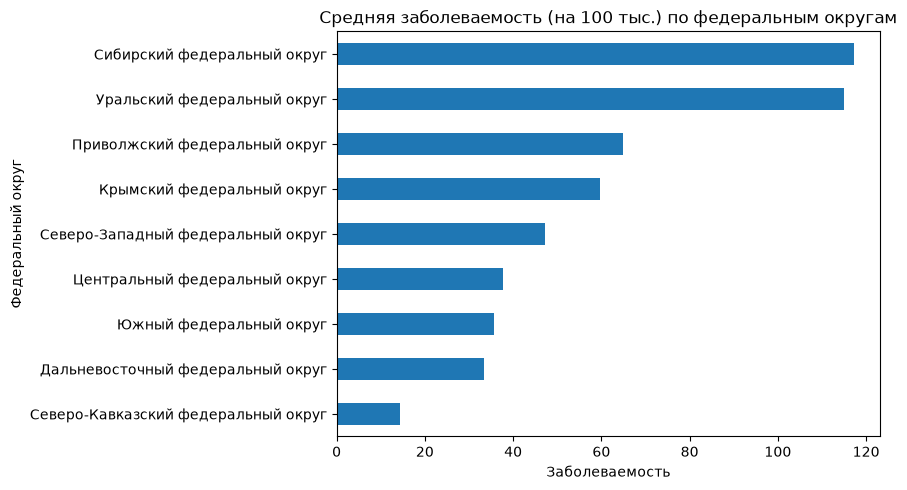

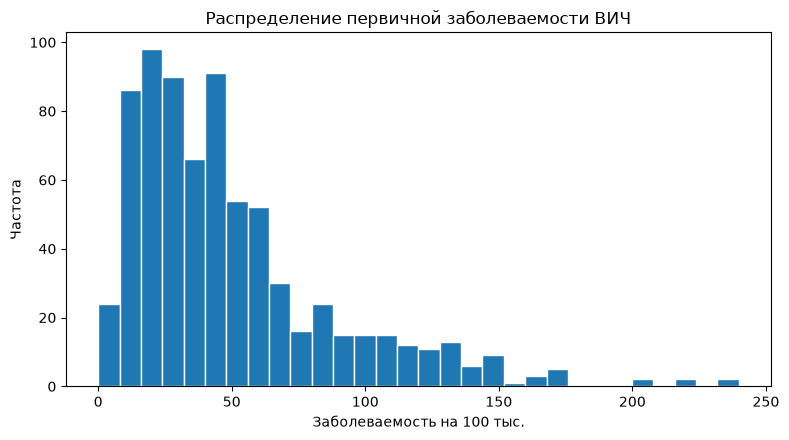

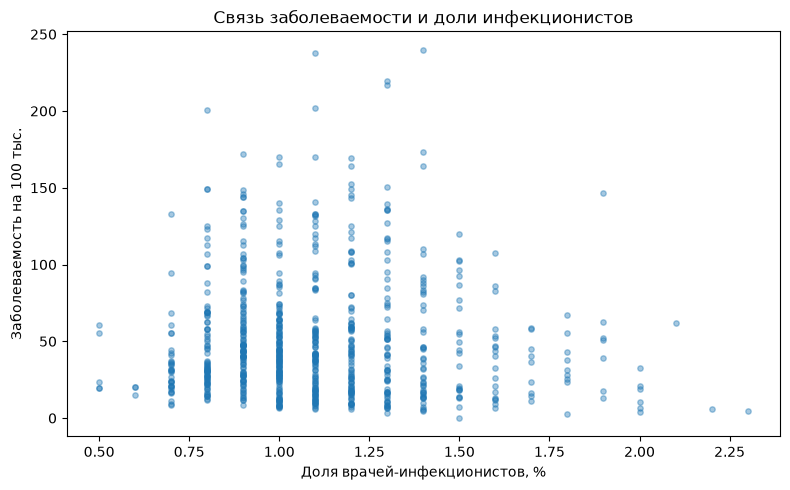

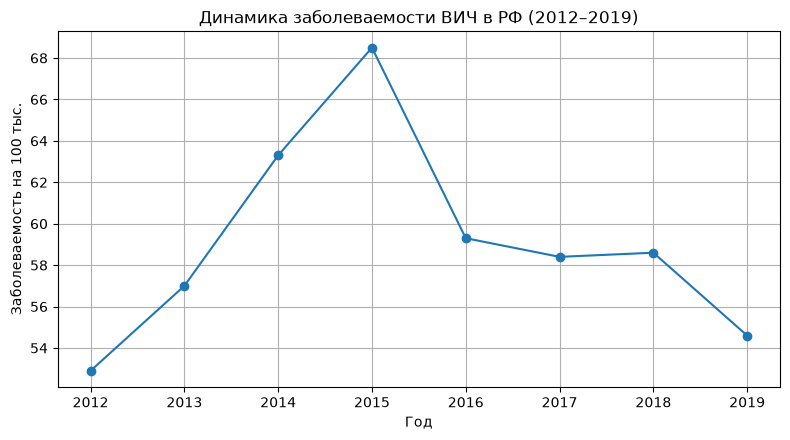

In [31]:
# Столбчатая диаграмма – средняя заболеваемость по округам (сравнение категорий)
districts_sorted = district_stats.sort_values("mean_incidence", ascending=True)
ax = districts_sorted["mean_incidence"].plot(kind="barh", figsize=(9,5))
ax.set_title("Средняя заболеваемость (на 100 тыс.) по федеральным округам")
ax.set_xlabel("Заболеваемость")
ax.set_ylabel("Федеральный округ")
plt.tight_layout()
plt.show()

# Гистограмма распределения заболеваемости
plt.figure(figsize=(8,4.5))
plt.hist(clean_df["hiv_firstdiagnosis_100k"].dropna(), bins=30, edgecolor="white")
plt.title("Распределение первичной заболеваемости ВИЧ")
plt.xlabel("Заболеваемость на 100 тыс.")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

# Scatter plot – заболеваемость vs доля инфекционистов
plt.figure(figsize=(8,5))
plt.scatter(
    clean_df["per_infectious_inalldoctors"],
    clean_df["hiv_firstdiagnosis_100k"],
    s=15, alpha=0.4
)
plt.xlabel("Доля врачей-инфекционистов, %")
plt.ylabel("Заболеваемость на 100 тыс.")
plt.title("Связь заболеваемости и доли инфекционистов")
plt.tight_layout()
plt.show()

# Временной ряд – средняя заболеваемость по годам (по России в целом)
russia = clean_df[clean_df["territory"] == "Российская Федерация"].sort_values("year")
plt.figure(figsize=(8,4.5))
plt.plot(russia["year"], russia["hiv_firstdiagnosis_100k"], marker="o", linestyle="-")
plt.title("Динамика заболеваемости ВИЧ в РФ (2012–2019)")
plt.xlabel("Год")
plt.ylabel("Заболеваемость на 100 тыс.")
plt.grid(True)
plt.tight_layout()
plt.show()

##### Графики наглядно подтверждают:

* Столбчатая диаграмма показывает резкое различие между округами – Сибирский и Уральский намного выше остальных.

* Гистограмма заболеваемости – большинство регионов имеют низкие показатели, но есть длинный правый хвост с высокими значениями.

* Scatter plot не показывает явной связи между долей инфекционистов и заболеваемостью, что согласуется с корреляцией.

* Временной ряд по России демонстрирует рост до 2015 года, затем снижение к 2019 году. Это важный вывод о динамике эпидемического процесса.

In [32]:
OUT = Path("output_self")
OUT.mkdir(exist_ok=True)

clean_df.to_csv(OUT / "hiv_clean.csv", index=False, encoding="utf-8")
clean_df.to_parquet(OUT / "hiv_clean.parquet", index=False, engine="pyarrow", compression="snappy")

files = [
    OUT / "hiv_clean.csv",
    OUT / "hiv_clean.parquet"
]
for path in files:
    size_mib = path.stat().st_size / 1024**2
    print(f"{path.name:24s} {size_mib:7.2f} MiB")

hiv_clean.csv               0.09 MiB
hiv_clean.parquet           0.05 MiB


##### Файлы сохранены. Размер CSV – 0.09 MiB, Parquet – 0.05 MiB. Parquet занимает почти вдвое меньше места благодаря колоночному сжатию и сохранению типов.

In [33]:
csv_back = pd.read_csv(OUT / "hiv_clean.csv")
parquet_back = pd.read_parquet(OUT / "hiv_clean.parquet")

print("CSV shape:", csv_back.shape)
print("Parquet shape:", parquet_back.shape)
print("\nТипы из Parquet:")
print(parquet_back.dtypes)

CSV shape: (760, 18)
Parquet shape: (760, 18)

Типы из Parquet:
territory                                 category
hiv_therapy_regdispensaries                float32
hiv_regdispensaries_numdetect              float32
hiv_firstdiagnosis_100k                    float32
hiv_motherchild_chemoprophylaxis           float32
hiv_regnum_firstdiagnosis                  float32
hiv_totalnumrussian_tested                 float32
hiv_russian_ibtestedpositive               float32
hiv_russian_ifatestedpositive              float32
hiv_totalnumforeign_tested                 float32
hiv_foreign_ibtestedpositive               float32
hiv_foreign_ifatestedpositive              float32
num_alldoctors_inmedorgservices            float32
num_infectiousdoctors_inmedorgservices     float32
per_infectious_inalldoctors                float32
year                                         int16
new_cases_per_inf_doctor                   float32
is_high_incidence                             bool
dtype: object


##### При повторном чтении оба файла имеют одинаковый размер (760, 18). Parquet корректно сохранил все типы: territory как категорию, year как int16, логический is_high_incidence как bool. Это подтверждает, что экспорт прошёл успешно и данные готовы к дальнейшему использованию в аналитическом конвейере.

##### **Выводы:**

1. Заболеваемость выросла с 40,9 (2012) до пика 55,8 (2015), затем снизилась до 49,4 (2019); охват терапией вырос с 32,6 % до 74,2 %.

2. Сибирский (117,3) и Уральский (114,9) округа лидируют по заболеваемости, Северо-Кавказский – минимален (14,5), разница > 8 раз.

3. Корреляции между заболеваемостью и долей инфекционистов (–0,03) или охватом терапией (–0,12) практически отсутствуют.

4. 50 регионов-лет превышают верхнюю границу IQR (124,7), в их числе Иркутская (до 200,9), Кемеровская, Новосибирская области – это реальные очаги высокой заболеваемости.

5. Тренд по РФ показывает рост до 2015 года, затем стабилизацию и небольшое снижение к 2019 году.

##### **Ограничения:**

1. Данные тестирования имеют ~39 % пропусков (за 2016–2018), что не позволяет анализировать охват и выявляемость полноценно.

2. Все показатели агрегированы по регионам – нет индивидуальных данных и внутрирегиональных различий, выводы носят макроуровневый характер.

##### **Контрольные вопросы**

1. Почему dtype числового столбца не гарантирует, что признак является количественным?

Числовой тип может хранить коды категорий, для которых среднее и сумма бессмысленны; смысл определяется предметной областью.

2. Чем DataFrame отличается от NumPy ndarray с точки зрения схемы и типов?

DataFrame – таблица с именованными столбцами разных типов; ndarray – однородный массив фиксированного типа.

3. Какие диагностические задачи решают head(), info() и describe() и почему одна функция не заменяет остальные?

head() – просмотр первых строк, info() – структура и типы, describe() – статистики; каждая даёт свой срез информации, необходимы все вместе.

4. Почему отсутствие пропусков и дубликатов ещё не означает отсутствие проблем качества данных?

Могут быть логические ошибки, неверные единицы, выбросы или некорректные коды – их не выявляют простые проверки.

5. В каких случаях category уменьшает память и почему?

Если уникальных значений мало относительно числа строк; хранит целочисленные коды вместо длинных строк.

6. Чем фильтрация отличается от группировки?

Фильтрация – отбор строк по условию; группировка – сжатие по условию.

7. Что означает коэффициент корреляции около нуля? Какие выводы из него делать нельзя?

Отсутствие линейной связи; нельзя делать вывод об отсутствии любой зависимости и о причинности.

8. Почему правило IQR нельзя использовать как автоматический алгоритм удаления данных?

Это эвристика, не учитывающая предметную область; аномалии могут быть значимыми данными, а не ошибками.

9. Как выбрать между histogram, bar chart, scatter plot и временным рядом?

Гистограмма – распределение одной числовой переменной; bar chart – сравнение категорий; scatter plot – связь двух числовых; временной ряд – динамика во времени.

10. Почему временной ряд нельзя строить по индексу строк, если индекс не является временем?

Индекс – только порядковый номер, не несёт календарной информации; график искажает реальную хронологию.

11. Какие преимущества Parquet даёт аналитическому pipeline по сравнению с CSV?

Сохраняет типы, сжимает, позволяет читать только нужные столбцы, быстрее и экономнее по памяти.

12. Почему воспроизводимый notebook должен корректно выполняться командой Run All после перезапуска ядра?

Гарантирует, что результаты не зависят от остаточных переменных и порядок вычислений логичен для любого пользователя.

### **Итоговый вывод по работе**

В ходе выполнения работы освоен полный цикл первичного анализа табличных данных: от создания изолированного Python-окружения до экспорта подготовленного набора в различные форматы. Отработаны ключевые методы Pandas – загрузка данных, диагностика пропусков и типов, оптимизация памяти, фильтрация, группировки, агрегации, построение корреляционных матриц и выявление потенциальных выбросов по правилу IQR. Закреплены навыки выбора визуализаций под конкретный аналитический вопрос и интерпретации полученных результатов с учётом предметной области.

Полученный инструментарий применим в широком спектре задач – от разведочного анализа социально-экономических показателей и медицинской статистики до обработки данных мониторинга и подготовки отчётности. Умение быстро оценить структуру данных, обнаружить аномалии, сформулировать содержательные выводы и сохранить результаты в воспроизводимом виде необходимо для любого аналитика, работающего с реальными несовершенными наборами данных, где качество и интерпретация играют не меньшую роль, чем код.